In [1]:
#SmartSense Anomaly Detection Setup

from pathlib import Path
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import OneHotEncoder

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Project paths
DATA_DIR = Path("data/us")

# Load dataset partitions
with open(DATA_DIR / "trn_instance_10.pkl", "rb") as f:
    train = pickle.load(f)

with open(DATA_DIR / "vld_instance_10.pkl", "rb") as f:
    val = pickle.load(f)

with open(DATA_DIR / "test_instance_10.pkl", "rb") as f:
    test = pickle.load(f)

# GPU setup
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Dataset shapes
print("\nDataset shapes:")
print("Training:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

# Validate expected sequence structure
for name, data in [
    ("Training", train),
    ("Validation", val),
    ("Test", test)
]:
    assert isinstance(data, np.ndarray)
    assert data.ndim == 3
    assert data.shape[1:] == (10, 5)

print("\nAll dataset checks passed!")


Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU

Dataset shapes:
Training: (47516, 10, 5)
Validation: (6789, 10, 5)
Test: (13577, 10, 5)

All dataset checks passed!


In [2]:
#Inspect anomaly detection data characteristics

from collections import Counter

FEATURE_NAMES = [
    "day_id",
    "time_id",
    "device_id",
    "column3_id",
    "device_control_id"
]

# 1. Inspect feature values and cardinalities
feature_summary = []

for feature_idx, feature_name in enumerate(FEATURE_NAMES):

    values = train[:, :, feature_idx].ravel()

    feature_summary.append({
        "Feature": feature_name,
        "Unique Values": len(np.unique(values)),
        "Minimum ID": int(values.min()),
        "Maximum ID": int(values.max())
    })

feature_summary_df = pd.DataFrame(feature_summary)

print("Feature summary:")
display(feature_summary_df)

# 2. Count complete 10-event sequences
window_keys = [
    window.tobytes()
    for window in train
]

window_counts = Counter(window_keys)

unique_windows = len(window_counts)

duplicate_copies = sum(
    count - 1
    for count in window_counts.values()
)

print("\nTraining window uniqueness:")
print("Total windows:", len(train))
print("Unique windows:", unique_windows)
print("Duplicate copies:", duplicate_copies)

# 3. Distribution of window frequencies
frequency_counts = Counter(window_counts.values())

window_frequency_df = pd.DataFrame(
    sorted(frequency_counts.items()),
    columns=["Occurrences", "Unique Windows"]
)

print("\nWindow occurrence distribution:")
display(window_frequency_df.head(15))

# 4. Count unique device-control actions per window
unique_action_counts = np.array([
    len(np.unique(window[:, 4]))
    for window in train
])

print("\nUnique actions per window:")
print(
    pd.Series(unique_action_counts).describe()
)

# 5. Inspect rare device-control actions
action_counts = pd.Series(
    train[:, :, 4].ravel()
).value_counts()

print("\nTotal observed action categories:", len(action_counts))

print("\nTen least frequent actions:")
display(action_counts.tail(10))

print("\nExploratory anomaly inspection complete!")


Feature summary:


,Feature,Unique Values,Minimum ID,Maximum ID
0,day_id,7,0,6
1,time_id,8,0,7
2,device_id,25,0,39
3,column3_id,37,0,43
4,device_control_id,134,0,265



Training window uniqueness:
Total windows: 47516
Unique windows: 47211
Duplicate copies: 305

Window occurrence distribution:


,Occurrences,Unique Windows
0,1,47079
1,2,65
2,3,40
3,4,17
4,5,2
5,6,2
6,8,1
7,13,1
8,15,1
9,17,1



Unique actions per window:
count    47516.000000
mean         3.117034
std          1.402379
min          1.000000
25%          2.000000
50%          3.000000
75%          4.000000
max         10.000000
dtype: float64

Total observed action categories: 134

Ten least frequent actions:


44     6
73     6
55     5
23     5
156    3
75     3
165    2
129    2
21     1
112    1
Name: count, dtype: int64


Exploratory anomaly inspection complete!


In [3]:
#Investigate device-action relationships

# Flatten training windows into individual events
train_events = train.reshape(-1, 5)

# Create event-level table
event_df = pd.DataFrame(
    train_events,
    columns=FEATURE_NAMES
)

# Count device-action combinations
device_action_counts = (
    event_df
    .groupby(["device_id", "device_control_id"])
    .size()
    .reset_index(name="Count")
)

# Count distinct actions per device
device_action_summary = (
    device_action_counts
    .groupby("device_id")
    .agg(
        Unique_Actions=("device_control_id", "nunique"),
        Total_Events=("Count", "sum")
    )
    .reset_index()
    .sort_values("Total_Events", ascending=False)
)

print("Device-action relationship summary:")
display(device_action_summary)

# Number of unique observed device-action pairs
observed_pairs = len(device_action_counts)

num_devices = event_df["device_id"].nunique()
num_actions = event_df["device_control_id"].nunique()

possible_pairs = num_devices * num_actions

print("\nObserved device-action pairs:", observed_pairs)
print("Possible device-action pairs:", possible_pairs)

print(
    "Observed pair coverage:",
    f"{observed_pairs / possible_pairs * 100:.2f}%"
)

# Identify low-frequency device-action combinations
rare_pairs = device_action_counts[
    device_action_counts["Count"] < 10
].sort_values("Count")

print("\nDevice-action pairs with fewer than 10 events:")
print("Number of rare pairs:", len(rare_pairs))

display(rare_pairs.head(20))

# Check whether each action is associated with multiple devices
action_device_counts = (
    device_action_counts
    .groupby("device_control_id")["device_id"]
    .nunique()
)

print("\nActions associated with multiple device IDs:")
print(int((action_device_counts > 1).sum()))

print("\nDevice-action analysis complete!")


Device-action relationship summary:


,device_id,Unique_Actions,Total_Events
22,35,11,236116
12,15,7,155542
15,22,12,19990
0,0,9,8153
19,30,5,8027
10,11,6,7347
14,20,8,6076
21,34,4,5493
9,10,4,5329
20,31,3,4178



Observed device-action pairs: 137
Possible device-action pairs: 3350
Observed pair coverage: 4.09%

Device-action pairs with fewer than 10 events:
Number of rare pairs: 14


,device_id,device_control_id,Count
13,1,21,1
66,17,112,1
99,25,165,2
74,20,129,2
45,10,75,3
95,25,156,3
34,7,55,5
15,1,23,5
29,5,44,6
44,9,73,6



Actions associated with multiple device IDs:
3

Device-action analysis complete!


In [4]:
#Synthetic anomaly generation

import numpy as np
import pandas as pd

RNG = np.random.default_rng(42)

# Valid replacement events come from training data only
replacement_events = np.unique(
    train.reshape(-1, 5),
    axis=0
)

print("Unique valid training events:", len(replacement_events))


def generate_order_anomalies(data, rng):
    """
    Swap two distinct events in each sequence.
    Preserves complete event records and categorical validity.
    """

    anomalies = data.copy()
    n_windows, sequence_length, _ = anomalies.shape

    changed = np.zeros(n_windows, dtype=bool)

    for i in range(n_windows):

        window = anomalies[i]

        # Find event positions with different records
        possible_pairs = [
            (a, b)
            for a in range(sequence_length)
            for b in range(a + 1, sequence_length)
            if not np.array_equal(window[a], window[b])
        ]

        if not possible_pairs:
            continue

        a, b = possible_pairs[
            rng.integers(len(possible_pairs))
        ]

        window[[a, b]] = window[[b, a]]

        changed[i] = True

    return anomalies, changed


def generate_substitution_anomalies(data, rng):
    """
    Replace one event with a different valid training event.
    Preserves valid categorical combinations.
    """

    anomalies = data.copy()
    n_windows, sequence_length, _ = anomalies.shape

    changed = np.zeros(n_windows, dtype=bool)

    for i in range(n_windows):

        position = rng.integers(sequence_length)

        original_event = anomalies[i, position].copy()

        # Sample until replacement differs from original
        for _ in range(100):

            replacement = replacement_events[
                rng.integers(len(replacement_events))
            ]

            if not np.array_equal(
                replacement,
                original_event
            ):
                anomalies[i, position] = replacement
                changed[i] = True
                break

    return anomalies, changed


# Generate anomalies from validation windows
order_anomalies, order_changed = (
    generate_order_anomalies(val, RNG)
)

substitution_anomalies, substitution_changed = (
    generate_substitution_anomalies(val, RNG)
)

# Verify changes
print("\nSynthetic anomaly generation:")
print("Original validation windows:", len(val))

print(
    "Order anomalies changed:",
    int(order_changed.sum())
)

print(
    "Substitution anomalies changed:",
    int(substitution_changed.sum())
)

# Compare example windows
print("\nExample original window:")
display(
    pd.DataFrame(
        val[0],
        columns=FEATURE_NAMES
    )
)

print("\nExample order anomaly:")
display(
    pd.DataFrame(
        order_anomalies[0],
        columns=FEATURE_NAMES
    )
)

print("\nExample substitution anomaly:")
display(
    pd.DataFrame(
        substitution_anomalies[0],
        columns=FEATURE_NAMES
    )
)

print("\nSynthetic anomaly generation complete!")


Unique valid training events: 5446

Synthetic anomaly generation:
Original validation windows: 6789
Order anomalies changed: 6789
Substitution anomalies changed: 6789

Example original window:


,day_id,time_id,device_id,column3_id,device_control_id
0,2,6,15,1,108
1,2,6,15,2,102
2,3,3,15,1,108
3,3,4,15,0,107
4,3,6,15,1,108
5,3,7,15,0,107
6,4,3,15,1,108
7,4,4,15,0,107
8,4,4,15,1,108
9,4,5,15,0,107



Example order anomaly:


,day_id,time_id,device_id,column3_id,device_control_id
0,3,7,15,0,107
1,2,6,15,2,102
2,3,3,15,1,108
3,3,4,15,0,107
4,3,6,15,1,108
5,2,6,15,1,108
6,4,3,15,1,108
7,4,4,15,0,107
8,4,4,15,1,108
9,4,5,15,0,107



Example substitution anomaly:


,day_id,time_id,device_id,column3_id,device_control_id
0,2,6,15,1,108
1,2,6,15,2,102
2,3,3,15,1,108
3,3,4,15,0,107
4,3,6,15,1,108
5,3,7,15,0,107
6,4,3,15,1,108
7,6,0,20,3,130
8,4,4,15,1,108
9,4,5,15,0,107



Synthetic anomaly generation complete!


In [5]:
#Evaluate chronological consistency

import numpy as np
import pandas as pd

def count_temporal_violations(data):
    """
    Count adjacent events whose day/time encoding
    moves backward within a sequence.

    Assumes day_id and time_id are ordered categories.
    """

    day_ids = data[:, :, 0]
    time_ids = data[:, :, 1]

    # Combine day and time into one sortable index
    temporal_index = day_ids * 8 + time_ids

    # Compare consecutive events
    differences = np.diff(
        temporal_index,
        axis=1
    )

    violations = differences < 0

    return violations.sum(axis=1)


# Count temporal violations
original_violations = count_temporal_violations(val)

order_violations = count_temporal_violations(
    order_anomalies
)

substitution_violations = count_temporal_violations(
    substitution_anomalies
)

# Summarize results
temporal_results = pd.DataFrame({
    "Dataset": [
        "Original Validation",
        "Order Anomalies",
        "Substitution Anomalies"
    ],
    "Windows": [
        len(val),
        len(order_anomalies),
        len(substitution_anomalies)
    ],
    "Windows With Violations": [
        int((original_violations > 0).sum()),
        int((order_violations > 0).sum()),
        int((substitution_violations > 0).sum())
    ],
    "Mean Violations Per Window": [
        original_violations.mean(),
        order_violations.mean(),
        substitution_violations.mean()
    ]
})

temporal_results["Violation Rate (%)"] = (
    temporal_results["Windows With Violations"]
    / temporal_results["Windows"] * 100
)

print("Temporal consistency comparison:")
display(temporal_results.round(3))

# Compare against original windows
new_order_violations = (
    order_violations > original_violations
)

new_substitution_violations = (
    substitution_violations > original_violations
)

print("\nAnomalies introducing additional violations:")
print(
    "Order anomalies:",
    int(new_order_violations.sum())
)

print(
    "Substitution anomalies:",
    int(new_substitution_violations.sum())
)

print("\nTemporal consistency analysis complete!")


Temporal consistency comparison:


,Dataset,Windows,Windows With Violations,Mean Violations Per Window,Violation Rate (%)
0,Original Validation,6789,3940,0.710,58.035
1,Order Anomalies,6789,6002,1.986,88.408
2,Substitution Anomalies,6789,6353,1.451,93.578



Anomalies introducing additional violations:
Order anomalies: 5452
Substitution anomalies: 5051

Temporal consistency analysis complete!


In [6]:
#Generate time-preserving contextual anomalies

import numpy as np
import pandas as pd

RNG_CONTEXT = np.random.default_rng(123)

# Extract valid device-related combinations from training
valid_device_combinations = np.unique(
    train[:, :, 2:5].reshape(-1, 3),
    axis=0
)

print(
    "Unique valid device-related combinations:",
    len(valid_device_combinations)
)


def generate_context_anomalies(data, rng):
    """
    Replace device-related features while preserving
    the original day and time IDs.

    Columns:
    0 = day_id (unchanged)
    1 = time_id (unchanged)
    2 = device_id
    3 = column3_id
    4 = device_control_id
    """

    anomalies = data.copy()
    n_windows, sequence_length, _ = anomalies.shape

    changed = np.zeros(n_windows, dtype=bool)

    for i in range(n_windows):

        position = rng.integers(sequence_length)

        original = anomalies[i, position, 2:5].copy()

        for _ in range(100):

            replacement = valid_device_combinations[
                rng.integers(len(valid_device_combinations))
            ]

            if not np.array_equal(replacement, original):

                anomalies[i, position, 2:5] = replacement
                changed[i] = True
                break

    return anomalies, changed


# Generate contextual anomalies from validation data
context_anomalies, context_changed = (
    generate_context_anomalies(val, RNG_CONTEXT)
)

# Verify modifications
print("\nContext anomalies generated:", int(context_changed.sum()))

# Confirm day/time features are unchanged
time_preserved = np.array_equal(
    context_anomalies[:, :, :2],
    val[:, :, :2]
)

print("Day/time features preserved:", time_preserved)

# Check temporal violation counts
context_violations = count_temporal_violations(
    context_anomalies
)

print(
    "Temporal violations unchanged:",
    np.array_equal(
        context_violations,
        original_violations
    )
)

# Verify every changed device combination is observed in training
valid_combo_set = {
    tuple(row)
    for row in valid_device_combinations
}

all_combinations_valid = all(
    tuple(row) in valid_combo_set
    for row in context_anomalies[:, :, 2:5].reshape(-1, 3)
    if not np.array_equal(row, np.array([-1, -1, -1]))
)

print(
    "All device combinations observed in training:",
    all_combinations_valid
)

# Show example
print("\nOriginal validation sequence:")
display(
    pd.DataFrame(
        val[0],
        columns=FEATURE_NAMES
    )
)

print("\nContextual anomaly:")
display(
    pd.DataFrame(
        context_anomalies[0],
        columns=FEATURE_NAMES
    )
)

print("\nContextual anomaly generation complete!")


Unique valid device-related combinations: 319

Context anomalies generated: 6789
Day/time features preserved: True
Temporal violations unchanged: True
All device combinations observed in training: False

Original validation sequence:


,day_id,time_id,device_id,column3_id,device_control_id
0,2,6,15,1,108
1,2,6,15,2,102
2,3,3,15,1,108
3,3,4,15,0,107
4,3,6,15,1,108
5,3,7,15,0,107
6,4,3,15,1,108
7,4,4,15,0,107
8,4,4,15,1,108
9,4,5,15,0,107



Contextual anomaly:


,day_id,time_id,device_id,column3_id,device_control_id
0,2,6,25,1,167
1,2,6,15,2,102
2,3,3,15,1,108
3,3,4,15,0,107
4,3,6,15,1,108
5,3,7,15,0,107
6,4,3,15,1,108
7,4,4,15,0,107
8,4,4,15,1,108
9,4,5,15,0,107



Contextual anomaly generation complete!


In [7]:
#Diagnose contextual anomaly validity

import numpy as np
import pandas as pd

# Build a set of valid device-related combinations
training_combo_set = {
    tuple(row.tolist())
    for row in valid_device_combinations
}

def find_unknown_combinations(data):
    """
    Return a boolean mask identifying device-related
    combinations not observed in training.
    """

    combos = data[:, :, 2:5]

    unknown = np.array([
        tuple(row.tolist()) not in training_combo_set
        for row in combos.reshape(-1, 3)
    ])

    return unknown.reshape(
        data.shape[0],
        data.shape[1]
    )


# Identify unknown combinations in original validation data
original_unknown = find_unknown_combinations(val)

# Identify unknown combinations in contextual anomalies
context_unknown = find_unknown_combinations(context_anomalies)

# Identify exactly which events changed
changed_events = np.any(
    val[:, :, 2:5] != context_anomalies[:, :, 2:5],
    axis=2
)

# Unknown combinations specifically introduced by modification
introduced_unknown = (
    context_unknown & changed_events
)

print("Original validation unknown combinations:",
      int(original_unknown.sum()))

print("Context anomaly unknown combinations:",
      int(context_unknown.sum()))

print("Changed events:",
      int(changed_events.sum()))

print("Unknown combinations introduced by generator:",
      int(introduced_unknown.sum()))

# Verify all changed events use observed combinations
assert introduced_unknown.sum() == 0, (
    "Generator introduced a combination absent from training."
)

# Summarize findings
diagnostic_summary = pd.DataFrame({
    "Metric": [
        "Unknown combinations in original validation",
        "Unknown combinations in contextual anomalies",
        "Changed events",
        "New unknown combinations introduced"
    ],
    "Count": [
        int(original_unknown.sum()),
        int(context_unknown.sum()),
        int(changed_events.sum()),
        int(introduced_unknown.sum())
    ]
})

display(diagnostic_summary)

print("\nContextual anomaly validity check passed!")


Original validation unknown combinations: 2
Context anomaly unknown combinations: 2
Changed events: 6789
Unknown combinations introduced by generator: 0


,Metric,Count
0,Unknown combinations in original validation,2
1,Unknown combinations in contextual anomalies,2
2,Changed events,6789
3,New unknown combinations introduced,0



Contextual anomaly validity check passed!


In [8]:
#Build synthetic anomaly evaluation dataset

import numpy as np
import pandas as pd

# Original validation sequences
X_normal = val.copy()

# Synthetic contextual anomalies
X_anomaly = context_anomalies.copy()

# Create balanced evaluation dataset
X_eval = np.concatenate(
    [X_normal, X_anomaly],
    axis=0
)

# Binary experimental labels
y_eval = np.concatenate([
    np.zeros(len(X_normal), dtype=np.int64),
    np.ones(len(X_anomaly), dtype=np.int64)
])

# Track source type
eval_source = np.array(
    ["Original"] * len(X_normal)
    + ["Contextual Anomaly"] * len(X_anomaly)
)

# Verify structure
assert X_eval.shape[1:] == (10, 5)
assert len(X_eval) == len(y_eval)

assert np.array_equal(
    X_eval[:len(val)],
    val
)

assert np.array_equal(
    X_eval[len(val):],
    context_anomalies
)

print("Evaluation dataset shape:", X_eval.shape)

print("\nLabel distribution:")
display(
    pd.Series(y_eval)
    .value_counts()
    .sort_index()
    .rename_axis("Label")
    .reset_index(name="Sequences")
)

print("\nEvaluation dataset composition:")
display(
    pd.Series(eval_source)
    .value_counts()
    .rename_axis("Source")
    .reset_index(name="Sequences")
)

print("\nSynthetic anomaly evaluation dataset ready!")


Evaluation dataset shape: (13578, 10, 5)

Label distribution:


,Label,Sequences
0,0,6789
1,1,6789



Evaluation dataset composition:


,Source,Sequences
0,Original,6789
1,Contextual Anomaly,6789



Synthetic anomaly evaluation dataset ready!


In [9]:
#Isolation Forest anomaly detection

import time
import numpy as np
import pandas as pd

from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Flatten each 10-event sequence into 50 categorical features
X_train_flat = train.reshape(len(train), -1)
X_eval_flat = X_eval.reshape(len(X_eval), -1)

print("Flattened training shape:", X_train_flat.shape)
print("Flattened evaluation shape:", X_eval_flat.shape)

# Fit encoder on training data only
anomaly_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)

X_train_encoded = anomaly_encoder.fit_transform(
    X_train_flat
)

X_eval_encoded = anomaly_encoder.transform(
    X_eval_flat
)

print("\nEncoded training shape:", X_train_encoded.shape)
print("Encoded evaluation shape:", X_eval_encoded.shape)

# Train Isolation Forest
isolation_forest = IsolationForest(
    n_estimators=200,
    max_samples=256,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

isolation_forest.fit(X_train_encoded)

training_time = time.time() - start_time

# Higher score = more anomalous
isolation_scores = -isolation_forest.score_samples(
    X_eval_encoded
)

# Evaluate using synthetic labels
isolation_roc_auc = roc_auc_score(
    y_eval,
    isolation_scores
)

isolation_pr_auc = average_precision_score(
    y_eval,
    isolation_scores
)

print("\nIsolation Forest Results")
print("-" * 40)

print(f"Training time: {training_time:.2f} seconds")
print(f"ROC-AUC: {isolation_roc_auc:.4f}")
print(f"Average Precision: {isolation_pr_auc:.4f}")

# Compare score distributions
score_summary = pd.DataFrame({
    "Group": ["Original", "Synthetic Anomaly"],
    "Mean Score": [
        isolation_scores[y_eval == 0].mean(),
        isolation_scores[y_eval == 1].mean()
    ],
    "Median Score": [
        np.median(isolation_scores[y_eval == 0]),
        np.median(isolation_scores[y_eval == 1])
    ],
    "Standard Deviation": [
        isolation_scores[y_eval == 0].std(),
        isolation_scores[y_eval == 1].std()
    ]
})

print("\nAnomaly score summary:")
display(score_summary.round(4))


Flattened training shape: (47516, 50)
Flattened evaluation shape: (13578, 50)

Encoded training shape: (47516, 1996)
Encoded evaluation shape: (13578, 1996)

Isolation Forest Results
----------------------------------------
Training time: 0.89 seconds
ROC-AUC: 0.5328
Average Precision: 0.5130

Anomaly score summary:


,Group,Mean Score,Median Score,Standard Deviation
0,Original,0.3656,0.3631,0.0104
1,Synthetic Anomaly,0.3663,0.3644,0.0098


In [10]:
#Frequency-based anomaly detection baseline

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Extract device-related combinations from training
train_combos = train[:, :, 2:5].reshape(-1, 3)

# Count occurrences of each combination
combo_counts = (
    pd.DataFrame(
        train_combos,
        columns=[
            "device_id",
            "column3_id",
            "device_control_id"
        ]
    )
    .value_counts()
    .to_dict()
)

total_train_events = len(train_combos)

# Laplace smoothing
alpha = 1.0
num_combos = len(combo_counts)


def frequency_anomaly_scores(data):
    """
    Score each sequence using the least likely
    device-related combination in the window.

    Higher score = more anomalous.
    """

    scores = []

    for window in data:

        event_scores = []

        for event in window:

            combo = tuple(
                int(value)
                for value in event[2:5]
            )

            count = combo_counts.get(combo, 0)

            probability = (
                (count + alpha)
                / (
                    total_train_events
                    + alpha * (num_combos + 1)
                )
            )

            event_scores.append(
                -np.log(probability)
            )

        # Highest event surprise in the sequence
        scores.append(max(event_scores))

    return np.array(scores)


frequency_scores = frequency_anomaly_scores(X_eval)

frequency_roc_auc = roc_auc_score(
    y_eval,
    frequency_scores
)

frequency_pr_auc = average_precision_score(
    y_eval,
    frequency_scores
)

print("Frequency-Based Anomaly Detector")
print("-" * 40)

print(f"ROC-AUC: {frequency_roc_auc:.4f}")
print(f"Average Precision: {frequency_pr_auc:.4f}")

frequency_summary = pd.DataFrame({
    "Group": ["Original", "Synthetic Anomaly"],
    "Mean Score": [
        frequency_scores[y_eval == 0].mean(),
        frequency_scores[y_eval == 1].mean()
    ],
    "Median Score": [
        np.median(frequency_scores[y_eval == 0]),
        np.median(frequency_scores[y_eval == 1])
    ]
})

print("\nFrequency score summary:")
display(frequency_summary.round(4))


Frequency-Based Anomaly Detector
----------------------------------------
ROC-AUC: 0.9251
Average Precision: 0.9215

Frequency score summary:


,Group,Mean Score,Median Score
0,Original,4.6191,4.5769
1,Synthetic Anomaly,9.2707,9.6709


In [11]:
#Frequency-matched contextual anomaly generation

import numpy as np
import pandas as pd

RNG_MATCHED = np.random.default_rng(456)

# Training device-related combinations
training_combos = train[:, :, 2:5].reshape(-1, 3)

# Unique combinations and their observed frequencies
unique_combos, combo_frequencies = np.unique(
    training_combos,
    axis=0,
    return_counts=True
)

# Empirical sampling probabilities
combo_probabilities = (
    combo_frequencies / combo_frequencies.sum()
)

print("Unique device combinations:", len(unique_combos))
print(
    "Probability sum:",
    combo_probabilities.sum()
)


def generate_frequency_matched_anomalies(data, rng):
    """
    Replace one device-related combination per window,
    sampling according to empirical training frequencies.

    Preserve day/time features.
    """

    anomalies = data.copy()
    n_windows, sequence_length, _ = anomalies.shape

    changed = np.zeros(n_windows, dtype=bool)

    for i in range(n_windows):

        position = rng.integers(sequence_length)

        original = anomalies[i, position, 2:5].copy()

        for _ in range(100):

            idx = rng.choice(
                len(unique_combos),
                p=combo_probabilities
            )

            replacement = unique_combos[idx]

            if not np.array_equal(
                replacement,
                original
            ):

                anomalies[i, position, 2:5] = replacement
                changed[i] = True
                break

    return anomalies, changed


# Generate matched anomalies
matched_anomalies, matched_changed = (
    generate_frequency_matched_anomalies(
        val,
        RNG_MATCHED
    )
)

# Verify results
print("\nMatched anomalies generated:",
      int(matched_changed.sum()))

print(
    "Day/time preserved:",
    np.array_equal(
        matched_anomalies[:, :, :2],
        val[:, :, :2]
    )
)

# Build evaluation dataset
X_eval_matched = np.concatenate(
    [val, matched_anomalies],
    axis=0
)

y_eval_matched = np.concatenate([
    np.zeros(len(val), dtype=np.int64),
    np.ones(len(matched_anomalies), dtype=np.int64)
])

print("\nMatched evaluation shape:",
      X_eval_matched.shape)

print(
    "Label distribution:",
    np.bincount(y_eval_matched)
)

print("\nFrequency-matched evaluation dataset ready!")


Unique device combinations: 319
Probability sum: 1.0

Matched anomalies generated: 6789
Day/time preserved: True

Matched evaluation shape: (13578, 10, 5)
Label distribution: [6789 6789]

Frequency-matched evaluation dataset ready!


In [12]:
#Compare anomaly detectors across datasets

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# --------------------------------------------------
# 1. Score the frequency-informed evaluation dataset
# --------------------------------------------------

# Flatten and encode using training-fitted encoder
X_eval_matched_flat = X_eval_matched.reshape(
    len(X_eval_matched), -1
)

X_eval_matched_encoded = anomaly_encoder.transform(
    X_eval_matched_flat
)

# Isolation Forest anomaly scores
isolation_scores_matched = (
    -isolation_forest.score_samples(
        X_eval_matched_encoded
    )
)

# Frequency-based anomaly scores
frequency_scores_matched = frequency_anomaly_scores(
    X_eval_matched
)

# --------------------------------------------------
# 2. Evaluate both detectors
# --------------------------------------------------

comparison_rows = []

datasets = {
    "Uniform Contextual": {
        "labels": y_eval,
        "Isolation Forest": isolation_scores,
        "Frequency Baseline": frequency_scores
    },
    "Frequency-Informed Contextual": {
        "labels": y_eval_matched,
        "Isolation Forest": isolation_scores_matched,
        "Frequency Baseline": frequency_scores_matched
    }
}

for dataset_name, dataset_info in datasets.items():

    labels = dataset_info["labels"]

    for model_name in [
        "Isolation Forest",
        "Frequency Baseline"
    ]:

        scores = dataset_info[model_name]

        comparison_rows.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "ROC-AUC": roc_auc_score(
                labels, scores
            ),
            "Average Precision": average_precision_score(
                labels, scores
            )
        })

anomaly_comparison = pd.DataFrame(comparison_rows)

print("Anomaly Detection Comparison:")
display(anomaly_comparison.round(4))

# --------------------------------------------------
# 3. Compare score distributions
# --------------------------------------------------

score_rows = []

for dataset_name, dataset_info in datasets.items():

    labels = dataset_info["labels"]

    for model_name in [
        "Isolation Forest",
        "Frequency Baseline"
    ]:

        scores = dataset_info[model_name]

        score_rows.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Original Mean Score": scores[
                labels == 0
            ].mean(),
            "Synthetic Mean Score": scores[
                labels == 1
            ].mean()
        })

score_comparison = pd.DataFrame(score_rows)

print("\nScore distribution comparison:")
display(score_comparison.round(4))


Anomaly Detection Comparison:


,Dataset,Model,ROC-AUC,Average Precision
0,Uniform Contextual,Isolation Forest,0.5328,0.5130
1,Uniform Contextual,Frequency Baseline,0.9251,0.9215
2,Frequency-Informed Contextual,Isolation Forest,0.5300,0.5072
3,Frequency-Informed Contextual,Frequency Baseline,0.5724,0.5378



Score distribution comparison:


,Dataset,Model,Original Mean Score,Synthetic Mean Score
0,Uniform Contextual,Isolation Forest,0.3656,0.3663
1,Uniform Contextual,Frequency Baseline,4.6191,9.2707
2,Frequency-Informed Contextual,Isolation Forest,0.3656,0.3661
3,Frequency-Informed Contextual,Frequency Baseline,4.6191,5.0917


In [13]:
#Prepare categorical sequences for GRU anomaly detection

import numpy as np
import torch

from torch.utils.data import TensorDataset, DataLoader

# Build feature vocabularies from training only
anomaly_feature_mappings = []
anomaly_vocab_sizes = []

for feature_idx, feature_name in enumerate(FEATURE_NAMES):

    unique_values = np.unique(
        train[:, :, feature_idx]
    )

    # Reserve 0 for unseen categories
    mapping = {
        int(value): idx + 1
        for idx, value in enumerate(unique_values)
    }

    anomaly_feature_mappings.append(mapping)
    anomaly_vocab_sizes.append(len(mapping) + 1)

    print(
        f"{feature_name}: "
        f"{len(mapping)} categories, "
        f"vocab size {len(mapping) + 1}"
    )


def encode_anomaly_sequences(data):
    """Encode 10-event sequences using training vocabularies."""

    encoded = np.zeros(
        data.shape,
        dtype=np.int64
    )

    for feature_idx, mapping in enumerate(
        anomaly_feature_mappings
    ):

        values = data[:, :, feature_idx]

        encoded[:, :, feature_idx] = np.array([
            mapping.get(int(value), 0)
            for value in values.ravel()
        ]).reshape(values.shape)

    return encoded


# Encode training and validation sequences
train_encoded_gru = encode_anomaly_sequences(train)
val_encoded_gru = encode_anomaly_sequences(val)

# Encode frequency-informed synthetic anomalies
matched_encoded_gru = encode_anomaly_sequences(
    matched_anomalies
)

# Build training sequences for next-event prediction
# Input: events 1-9
# Target: device-control action of events 2-10
X_train_seq = train_encoded_gru[:, :-1, :]
y_train_seq = train_encoded_gru[:, 1:, 4]

print("\nSequence prediction shapes:")
print("Inputs:", X_train_seq.shape)
print("Targets:", y_train_seq.shape)

# Create DataLoader
ANOMALY_BATCH_SIZE = 256

train_seq_dataset = TensorDataset(
    torch.tensor(X_train_seq, dtype=torch.long),
    torch.tensor(y_train_seq, dtype=torch.long)
)

train_seq_loader = DataLoader(
    train_seq_dataset,
    batch_size=ANOMALY_BATCH_SIZE,
    shuffle=True
)

# Inspect batch
batch_X, batch_y = next(iter(train_seq_loader))

print("\nFirst training batch:")
print("X:", batch_X.shape)
print("y:", batch_y.shape)

print("\nGRU anomaly data preparation complete!")


day_id: 7 categories, vocab size 8
time_id: 8 categories, vocab size 9
device_id: 25 categories, vocab size 26
column3_id: 37 categories, vocab size 38
device_control_id: 134 categories, vocab size 135

Sequence prediction shapes:
Inputs: (47516, 9, 5)
Targets: (47516, 9)

First training batch:
X: torch.Size([256, 9, 5])
y: torch.Size([256, 9])

GRU anomaly data preparation complete!


In [14]:
#Define GRU sequence anomaly detector

import torch
import torch.nn as nn

class SmartSenseAnomalyGRU(nn.Module):

    def __init__(
        self,
        vocab_sizes,
        embedding_dim=8,
        hidden_dim=64,
        dropout=0.2
    ):
        super().__init__()

        # Separate embeddings for each categorical feature
        self.embeddings = nn.ModuleList([
            nn.Embedding(
                num_embeddings=vocab_size,
                embedding_dim=embedding_dim,
                padding_idx=0
            )
            for vocab_size in vocab_sizes
        ])

        input_dim = len(vocab_sizes) * embedding_dim

        # GRU processes event sequences
        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout)

        # Predict next device-control action at each step
        self.classifier = nn.Linear(
            hidden_dim,
            vocab_sizes[4]
        )

    def forward(self, x):

        # x: (batch, 9, 5)

        embedded_features = [
            embedding(x[:, :, idx])
            for idx, embedding in enumerate(self.embeddings)
        ]

        combined = torch.cat(
            embedded_features,
            dim=-1
        )

        # Output at every time step
        gru_output, _ = self.gru(combined)

        gru_output = self.dropout(gru_output)

        logits = self.classifier(gru_output)

        return logits


# Initialize model
anomaly_gru_model = SmartSenseAnomalyGRU(
    vocab_sizes=anomaly_vocab_sizes,
    embedding_dim=8,
    hidden_dim=64,
    dropout=0.2
).to(device)

print("GRU Anomaly Model Architecture:")
print(anomaly_gru_model)

# Count parameters
parameter_count = sum(
    p.numel()
    for p in anomaly_gru_model.parameters()
    if p.requires_grad
)

print("\nTrainable parameters:", parameter_count)

# Test GPU forward pass
batch_X, batch_y = next(iter(train_seq_loader))

batch_X = batch_X.to(device)

anomaly_gru_model.eval()

with torch.no_grad():
    logits = anomaly_gru_model(batch_X)

print("\nForward pass:")
print("Input shape:", batch_X.shape)
print("Output shape:", logits.shape)
print("Output device:", logits.device)

assert logits.shape == (
    batch_X.shape[0],
    9,
    anomaly_vocab_sizes[4]
)

print("\nGRU anomaly architecture verified!")


GRU Anomaly Model Architecture:
SmartSenseAnomalyGRU(
  (embeddings): ModuleList(
    (0): Embedding(8, 8, padding_idx=0)
    (1): Embedding(9, 8, padding_idx=0)
    (2): Embedding(26, 8, padding_idx=0)
    (3): Embedding(38, 8, padding_idx=0)
    (4): Embedding(135, 8, padding_idx=0)
  )
  (gru): GRU(40, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (classifier): Linear(in_features=64, out_features=135, bias=True)
)

Trainable parameters: 30855

Forward pass:
Input shape: torch.Size([256, 9, 5])
Output shape: torch.Size([256, 9, 135])
Output device: cuda:0

GRU anomaly architecture verified!


In [15]:
#Train GRU anomaly detector

import copy
import time

import torch
import torch.nn as nn
import torch.optim as optim

# Reproducibility
torch.manual_seed(42)

LEARNING_RATE = 0.001
MAX_EPOCHS = 30
PATIENCE = 5

# Ignore unknown index 0 for validation loss
criterion = nn.CrossEntropyLoss(
    ignore_index=0
)

optimizer = optim.Adam(
    anomaly_gru_model.parameters(),
    lr=LEARNING_RATE
)

# Validation next-action prediction dataset
X_val_seq = val_encoded_gru[:, :-1, :]
y_val_seq = val_encoded_gru[:, 1:, 4]

val_seq_dataset = TensorDataset(
    torch.tensor(X_val_seq, dtype=torch.long),
    torch.tensor(y_val_seq, dtype=torch.long)
)

val_seq_loader = DataLoader(
    val_seq_dataset,
    batch_size=ANOMALY_BATCH_SIZE,
    shuffle=False
)

anomaly_gru_history = {
    "train_loss": [],
    "val_loss": []
}

best_val_loss = float("inf")
best_model_state = None
best_epoch = 0
patience_counter = 0

start_time = time.time()

for epoch in range(MAX_EPOCHS):

    # -------------------------
    # Training
    # -------------------------
    anomaly_gru_model.train()

    total_train_loss = 0.0
    total_train_targets = 0

    for batch_X, batch_y in train_seq_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        logits = anomaly_gru_model(batch_X)

        # Remove unused unknown output class
        logits_known = logits[:, :, 1:]

        # Shift known target IDs from 1..134 to 0..133
        targets = batch_y - 1

        loss = nn.functional.cross_entropy(
            logits_known.reshape(-1, logits_known.size(-1)),
            targets.reshape(-1)
        )

        loss.backward()

        nn.utils.clip_grad_norm_(
            anomaly_gru_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        count = targets.numel()
        total_train_loss += loss.item() * count
        total_train_targets += count

    train_loss = total_train_loss / total_train_targets

    # -------------------------
    # Validation
    # -------------------------
    anomaly_gru_model.eval()

    total_val_loss = 0.0
    total_val_targets = 0

    with torch.no_grad():

        for batch_X, batch_y in val_seq_loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            logits = anomaly_gru_model(batch_X)

            logits_known = logits[:, :, 1:]
            targets = batch_y - 1

            # Known validation action categories
            known_mask = batch_y > 0

            if known_mask.any():

                loss = nn.functional.cross_entropy(
                    logits_known[known_mask],
                    targets[known_mask]
                )

                count = int(known_mask.sum().item())

                total_val_loss += loss.item() * count
                total_val_targets += count

    val_loss = total_val_loss / total_val_targets

    anomaly_gru_history["train_loss"].append(train_loss)
    anomaly_gru_history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    # -------------------------
    # Early stopping
    # -------------------------
    if val_loss < best_val_loss - 1e-4:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            anomaly_gru_model.state_dict()
        )

        patience_counter = 0

    else:
        patience_counter += 1

        if patience_counter >= PATIENCE:
            print("\nEarly stopping triggered.")
            break

# Restore best model
anomaly_gru_model.load_state_dict(best_model_state)

training_time = time.time() - start_time

print("\nGRU anomaly training complete!")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Training time:", round(training_time, 2), "seconds")


Epoch 01/30 | Train Loss: 2.4485 | Val Loss: 1.7492
Epoch 02/30 | Train Loss: 1.6339 | Val Loss: 1.4991
Epoch 03/30 | Train Loss: 1.4924 | Val Loss: 1.4293
Epoch 04/30 | Train Loss: 1.4387 | Val Loss: 1.3911
Epoch 05/30 | Train Loss: 1.4064 | Val Loss: 1.3675
Epoch 06/30 | Train Loss: 1.3849 | Val Loss: 1.3510
Epoch 07/30 | Train Loss: 1.3698 | Val Loss: 1.3394
Epoch 08/30 | Train Loss: 1.3577 | Val Loss: 1.3290
Epoch 09/30 | Train Loss: 1.3478 | Val Loss: 1.3210
Epoch 10/30 | Train Loss: 1.3396 | Val Loss: 1.3151
Epoch 11/30 | Train Loss: 1.3324 | Val Loss: 1.3085
Epoch 12/30 | Train Loss: 1.3259 | Val Loss: 1.3027
Epoch 13/30 | Train Loss: 1.3207 | Val Loss: 1.2984
Epoch 14/30 | Train Loss: 1.3144 | Val Loss: 1.2941
Epoch 15/30 | Train Loss: 1.3102 | Val Loss: 1.2902
Epoch 16/30 | Train Loss: 1.3053 | Val Loss: 1.2848
Epoch 17/30 | Train Loss: 1.3019 | Val Loss: 1.2816
Epoch 18/30 | Train Loss: 1.2980 | Val Loss: 1.2792
Epoch 19/30 | Train Loss: 1.2942 | Val Loss: 1.2769
Epoch 20/30 

In [16]:
#GRU anomaly scoring and evaluation

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

def gru_anomaly_scores(data, batch_size=256):
    """
    Calculate average next-action negative log-probability
    for each 10-event sequence.

    Higher score = more anomalous.

    Unknown target action IDs are excluded from the average.
    """

    encoded = encode_anomaly_sequences(data)

    X = torch.tensor(
        encoded[:, :-1, :],
        dtype=torch.long
    )

    y = torch.tensor(
        encoded[:, 1:, 4],
        dtype=torch.long
    )

    dataset = TensorDataset(X, y)

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False
    )

    anomaly_gru_model.eval()

    all_scores = []

    with torch.no_grad():

        for batch_X, batch_y in loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            logits = anomaly_gru_model(batch_X)

            # Use only known action classes
            logits_known = logits[:, :, 1:]

            log_probs = F.log_softmax(
                logits_known,
                dim=-1
            )

            # Targets encoded as 1..134
            known_mask = batch_y > 0

            safe_targets = torch.clamp(
                batch_y - 1,
                min=0
            )

            observed_log_probs = log_probs.gather(
                dim=-1,
                index=safe_targets.unsqueeze(-1)
            ).squeeze(-1)

            event_surprise = -observed_log_probs

            # Exclude unknown actions
            event_surprise = (
                event_surprise * known_mask
            )

            valid_counts = known_mask.sum(dim=1)

            sequence_scores = (
                event_surprise.sum(dim=1)
                / valid_counts.clamp(min=1)
            )

            all_scores.extend(
                sequence_scores.cpu().numpy()
            )

    return np.array(all_scores)


# Evaluate on both anomaly datasets
gru_scores_uniform = gru_anomaly_scores(X_eval)

gru_scores_matched = gru_anomaly_scores(
    X_eval_matched
)

gru_results = pd.DataFrame([
    {
        "Dataset": "Uniform Contextual",
        "ROC-AUC": roc_auc_score(
            y_eval,
            gru_scores_uniform
        ),
        "Average Precision": average_precision_score(
            y_eval,
            gru_scores_uniform
        )
    },
    {
        "Dataset": "Frequency-Informed Contextual",
        "ROC-AUC": roc_auc_score(
            y_eval_matched,
            gru_scores_matched
        ),
        "Average Precision": average_precision_score(
            y_eval_matched,
            gru_scores_matched
        )
    }
])

print("GRU Anomaly Detection Results:")
display(gru_results.round(4))

# Compare with previous detectors
all_results = pd.concat([
    anomaly_comparison,
    gru_results.assign(Model="GRU Anomaly Detector")
], ignore_index=True)

print("\nComplete Anomaly Detection Comparison:")
display(
    all_results.sort_values(
        ["Dataset", "ROC-AUC"],
        ascending=[True, False]
    ).round(4)
)

# Score distributions for frequency-informed dataset
matched_gru_summary = pd.DataFrame({
    "Group": ["Original", "Synthetic Anomaly"],
    "Mean Score": [
        gru_scores_matched[y_eval_matched == 0].mean(),
        gru_scores_matched[y_eval_matched == 1].mean()
    ],
    "Median Score": [
        np.median(
            gru_scores_matched[y_eval_matched == 0]
        ),
        np.median(
            gru_scores_matched[y_eval_matched == 1]
        )
    ]
})

print("\nGRU score distributions (frequency-informed):")
display(matched_gru_summary.round(4))


GRU Anomaly Detection Results:


,Dataset,ROC-AUC,Average Precision
0,Uniform Contextual,0.8526,0.8192
1,Frequency-Informed Contextual,0.7352,0.6860



Complete Anomaly Detection Comparison:


,Dataset,Model,ROC-AUC,Average Precision
5,Frequency-Informed Contextual,GRU Anomaly Detector,0.7352,0.6860
3,Frequency-Informed Contextual,Frequency Baseline,0.5724,0.5378
2,Frequency-Informed Contextual,Isolation Forest,0.5300,0.5072
1,Uniform Contextual,Frequency Baseline,0.9251,0.9215
4,Uniform Contextual,GRU Anomaly Detector,0.8526,0.8192
0,Uniform Contextual,Isolation Forest,0.5328,0.5130



GRU score distributions (frequency-informed):


,Group,Mean Score,Median Score
0,Original,1.2533,1.1210
1,Synthetic Anomaly,1.8137,1.7268


In [17]:
#Define categorical GRU sequence autoencoder

import torch
import torch.nn as nn

class SmartSenseAutoencoder(nn.Module):

    def __init__(
        self,
        vocab_sizes,
        embedding_dim=8,
        hidden_dim=64,
        dropout=0.2
    ):
        super().__init__()

        self.embeddings = nn.ModuleList([
            nn.Embedding(
                vocab_size,
                embedding_dim,
                padding_idx=0
            )
            for vocab_size in vocab_sizes
        ])

        input_dim = len(vocab_sizes) * embedding_dim

        # Encode the full sequence
        self.encoder = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        # Decode the compressed sequence representation
        self.decoder = nn.GRU(
            input_size=hidden_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout)

        # Separate output heads for categorical reconstruction
        self.device_head = nn.Linear(
            hidden_dim,
            vocab_sizes[2]
        )

        self.column3_head = nn.Linear(
            hidden_dim,
            vocab_sizes[3]
        )

        self.action_head = nn.Linear(
            hidden_dim,
            vocab_sizes[4]
        )

    def forward(self, x):

        # Embed categorical input features
        embedded = [
            embedding(x[:, :, idx])
            for idx, embedding in enumerate(self.embeddings)
        ]

        combined = torch.cat(embedded, dim=-1)

        # Encode sequence into final hidden state
        _, hidden = self.encoder(combined)

        # Repeat compressed representation across time steps
        repeated = hidden[-1].unsqueeze(1).repeat(
            1, x.size(1), 1
        )

        # Decode sequence
        decoded, _ = self.decoder(repeated)

        decoded = self.dropout(decoded)

        return {
            "device": self.device_head(decoded),
            "column3": self.column3_head(decoded),
            "action": self.action_head(decoded)
        }


# Initialize autoencoder
autoencoder_model = SmartSenseAutoencoder(
    vocab_sizes=anomaly_vocab_sizes,
    embedding_dim=8,
    hidden_dim=64,
    dropout=0.2
).to(device)

print("Autoencoder architecture:")
print(autoencoder_model)

parameter_count = sum(
    p.numel()
    for p in autoencoder_model.parameters()
    if p.requires_grad
)

print("\nTrainable parameters:", parameter_count)

# Test forward pass
sample_X = torch.tensor(
    train_encoded_gru[:256],
    dtype=torch.long,
    device=device
)

autoencoder_model.eval()

with torch.no_grad():
    outputs = autoencoder_model(sample_X)

print("\nForward-pass output shapes:")

for name, output in outputs.items():
    print(name, output.shape)

print("\nOutput device:", outputs["action"].device)
print("\nAutoencoder forward pass successful!")


Autoencoder architecture:
SmartSenseAutoencoder(
  (embeddings): ModuleList(
    (0): Embedding(8, 8, padding_idx=0)
    (1): Embedding(9, 8, padding_idx=0)
    (2): Embedding(26, 8, padding_idx=0)
    (3): Embedding(38, 8, padding_idx=0)
    (4): Embedding(135, 8, padding_idx=0)
  )
  (encoder): GRU(40, 64, batch_first=True)
  (decoder): GRU(64, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (device_head): Linear(in_features=64, out_features=26, bias=True)
  (column3_head): Linear(in_features=64, out_features=38, bias=True)
  (action_head): Linear(in_features=64, out_features=135, bias=True)
)

Trainable parameters: 59975

Forward-pass output shapes:
device torch.Size([256, 10, 26])
column3 torch.Size([256, 10, 38])
action torch.Size([256, 10, 135])

Output device: cuda:0

Autoencoder forward pass successful!


In [18]:
#Train categorical GRU sequence autoencoder

import copy
import time

import torch
import torch.nn.functional as F
import torch.optim as optim

# Create datasets from complete 10-event sequences
ae_train_dataset = TensorDataset(
    torch.tensor(train_encoded_gru, dtype=torch.long)
)

ae_val_dataset = TensorDataset(
    torch.tensor(val_encoded_gru, dtype=torch.long)
)

AE_BATCH_SIZE = 256

ae_train_loader = DataLoader(
    ae_train_dataset,
    batch_size=AE_BATCH_SIZE,
    shuffle=True
)

ae_val_loader = DataLoader(
    ae_val_dataset,
    batch_size=AE_BATCH_SIZE,
    shuffle=False
)

# Reconstruction loss for categorical features
def autoencoder_reconstruction_loss(outputs, targets):

    feature_losses = []

    for output_name, feature_idx in [
        ("device", 2),
        ("column3", 3),
        ("action", 4)
    ]:

        logits = outputs[output_name]

        target_values = targets[:, :, feature_idx]

        # Exclude unseen validation categories
        known_mask = target_values > 0

        if known_mask.any():

            loss = F.cross_entropy(
                logits[known_mask],
                target_values[known_mask]
            )

            feature_losses.append(loss)

    return torch.stack(feature_losses).mean()


# Training configuration
AE_LR = 0.001
AE_MAX_EPOCHS = 30
AE_PATIENCE = 5

ae_optimizer = optim.Adam(
    autoencoder_model.parameters(),
    lr=AE_LR
)

ae_history = {
    "train_loss": [],
    "val_loss": []
}

best_ae_val_loss = float("inf")
best_ae_state = None
best_ae_epoch = 0
ae_patience_counter = 0

ae_start_time = time.time()

for epoch in range(AE_MAX_EPOCHS):

    # -------------------------
    # Training
    # -------------------------
    autoencoder_model.train()

    train_loss_sum = 0.0
    train_examples = 0

    for (batch_X,) in ae_train_loader:

        batch_X = batch_X.to(device)

        ae_optimizer.zero_grad()

        outputs = autoencoder_model(batch_X)

        loss = autoencoder_reconstruction_loss(
            outputs,
            batch_X
        )

        loss.backward()

        nn.utils.clip_grad_norm_(
            autoencoder_model.parameters(),
            max_norm=1.0
        )

        ae_optimizer.step()

        train_loss_sum += (
            loss.item() * batch_X.size(0)
        )

        train_examples += batch_X.size(0)

    train_loss = train_loss_sum / train_examples

    # -------------------------
    # Validation
    # -------------------------
    autoencoder_model.eval()

    val_loss_sum = 0.0
    val_examples = 0

    with torch.no_grad():

        for (batch_X,) in ae_val_loader:

            batch_X = batch_X.to(device)

            outputs = autoencoder_model(batch_X)

            loss = autoencoder_reconstruction_loss(
                outputs,
                batch_X
            )

            val_loss_sum += (
                loss.item() * batch_X.size(0)
            )

            val_examples += batch_X.size(0)

    val_loss = val_loss_sum / val_examples

    ae_history["train_loss"].append(train_loss)
    ae_history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{AE_MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    # -------------------------
    # Early stopping
    # -------------------------
    if val_loss < best_ae_val_loss - 1e-4:

        best_ae_val_loss = val_loss
        best_ae_epoch = epoch + 1

        best_ae_state = copy.deepcopy(
            autoencoder_model.state_dict()
        )

        ae_patience_counter = 0

    else:
        ae_patience_counter += 1

        if ae_patience_counter >= AE_PATIENCE:
            print("\nEarly stopping triggered.")
            break

# Restore best checkpoint
autoencoder_model.load_state_dict(best_ae_state)

ae_training_time = time.time() - ae_start_time

print("\nAutoencoder training complete!")
print("Best epoch:", best_ae_epoch)
print(
    "Best validation loss:",
    round(best_ae_val_loss, 4)
)
print(
    "Training time:",
    round(ae_training_time, 2),
    "seconds"
)


Epoch 01/30 | Train Loss: 1.7367 | Val Loss: 1.2254
Epoch 02/30 | Train Loss: 1.1235 | Val Loss: 0.9866
Epoch 03/30 | Train Loss: 0.9660 | Val Loss: 0.8949
Epoch 04/30 | Train Loss: 0.9000 | Val Loss: 0.8471
Epoch 05/30 | Train Loss: 0.8597 | Val Loss: 0.8121
Epoch 06/30 | Train Loss: 0.8269 | Val Loss: 0.7804
Epoch 07/30 | Train Loss: 0.7974 | Val Loss: 0.7509
Epoch 08/30 | Train Loss: 0.7691 | Val Loss: 0.7212
Epoch 09/30 | Train Loss: 0.7381 | Val Loss: 0.6920
Epoch 10/30 | Train Loss: 0.7101 | Val Loss: 0.6594
Epoch 11/30 | Train Loss: 0.6824 | Val Loss: 0.6323
Epoch 12/30 | Train Loss: 0.6543 | Val Loss: 0.6032
Epoch 13/30 | Train Loss: 0.6272 | Val Loss: 0.5776
Epoch 14/30 | Train Loss: 0.6031 | Val Loss: 0.5615
Epoch 15/30 | Train Loss: 0.5819 | Val Loss: 0.5367
Epoch 16/30 | Train Loss: 0.5621 | Val Loss: 0.5161
Epoch 17/30 | Train Loss: 0.5459 | Val Loss: 0.5014
Epoch 18/30 | Train Loss: 0.5283 | Val Loss: 0.4823
Epoch 19/30 | Train Loss: 0.5095 | Val Loss: 0.4714
Epoch 20/30 

In [19]:
#Autoencoder anomaly scoring and comparison

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)


def autoencoder_anomaly_scores(data, batch_size=256):
    """
    Calculate mean categorical reconstruction surprise.

    Higher score = more anomalous.
    Unknown feature categories are excluded.
    """

    encoded = encode_anomaly_sequences(data)

    dataset = TensorDataset(
        torch.tensor(encoded, dtype=torch.long)
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False
    )

    autoencoder_model.eval()

    all_scores = []

    with torch.no_grad():

        for (batch_X,) in loader:

            batch_X = batch_X.to(device)

            outputs = autoencoder_model(batch_X)

            feature_scores = []

            for name, feature_idx in [
                ("device", 2),
                ("column3", 3),
                ("action", 4)
            ]:

                logits = outputs[name]
                targets = batch_X[:, :, feature_idx]

                log_probs = F.log_softmax(
                    logits,
                    dim=-1
                )

                # Avoid invalid indices
                safe_targets = targets.clamp(
                    min=0,
                    max=logits.size(-1) - 1
                )

                observed_log_probs = log_probs.gather(
                    dim=-1,
                    index=safe_targets.unsqueeze(-1)
                ).squeeze(-1)

                surprise = -observed_log_probs

                # Ignore unknown categories
                known_mask = targets > 0

                surprise = surprise * known_mask

                valid_counts = known_mask.sum(dim=1)

                sequence_feature_score = (
                    surprise.sum(dim=1)
                    / valid_counts.clamp(min=1)
                )

                feature_scores.append(
                    sequence_feature_score
                )

            # Average across reconstructed features
            sequence_scores = torch.stack(
                feature_scores,
                dim=1
            ).mean(dim=1)

            all_scores.extend(
                sequence_scores.cpu().numpy()
            )

    return np.array(all_scores)


# Calculate autoencoder scores
ae_scores_uniform = autoencoder_anomaly_scores(
    X_eval
)

ae_scores_matched = autoencoder_anomaly_scores(
    X_eval_matched
)

# Evaluate
ae_results = pd.DataFrame([
    {
        "Dataset": "Uniform Contextual",
        "Model": "GRU Autoencoder",
        "ROC-AUC": roc_auc_score(
            y_eval,
            ae_scores_uniform
        ),
        "Average Precision": average_precision_score(
            y_eval,
            ae_scores_uniform
        )
    },
    {
        "Dataset": "Frequency-Informed Contextual",
        "Model": "GRU Autoencoder",
        "ROC-AUC": roc_auc_score(
            y_eval_matched,
            ae_scores_matched
        ),
        "Average Precision": average_precision_score(
            y_eval_matched,
            ae_scores_matched
        )
    }
])

print("GRU Autoencoder Results:")
display(ae_results.round(4))

# Combine all four models
complete_anomaly_results = pd.concat(
    [
        all_results,
        ae_results
    ],
    ignore_index=True
)

print("\nComplete Anomaly Detection Comparison:")
display(
    complete_anomaly_results.sort_values(
        ["Dataset", "ROC-AUC"],
        ascending=[True, False]
    ).round(4)
)

# Score distributions for frequency-informed anomalies
ae_score_summary = pd.DataFrame({
    "Group": ["Original", "Synthetic Anomaly"],
    "Mean Score": [
        ae_scores_matched[y_eval_matched == 0].mean(),
        ae_scores_matched[y_eval_matched == 1].mean()
    ],
    "Median Score": [
        np.median(
            ae_scores_matched[y_eval_matched == 0]
        ),
        np.median(
            ae_scores_matched[y_eval_matched == 1]
        )
    ]
})

print("\nAutoencoder score distributions:")
display(ae_score_summary.round(4))


GRU Autoencoder Results:


,Dataset,Model,ROC-AUC,Average Precision
0,Uniform Contextual,GRU Autoencoder,0.8316,0.7690
1,Frequency-Informed Contextual,GRU Autoencoder,0.6712,0.6159



Complete Anomaly Detection Comparison:


,Dataset,Model,ROC-AUC,Average Precision
5,Frequency-Informed Contextual,GRU Anomaly Detector,0.7352,0.6860
7,Frequency-Informed Contextual,GRU Autoencoder,0.6712,0.6159
3,Frequency-Informed Contextual,Frequency Baseline,0.5724,0.5378
2,Frequency-Informed Contextual,Isolation Forest,0.5300,0.5072
1,Uniform Contextual,Frequency Baseline,0.9251,0.9215
4,Uniform Contextual,GRU Anomaly Detector,0.8526,0.8192
6,Uniform Contextual,GRU Autoencoder,0.8316,0.7690
0,Uniform Contextual,Isolation Forest,0.5328,0.5130



Autoencoder score distributions:


,Group,Mean Score,Median Score
0,Original,0.3303,0.1969
1,Synthetic Anomaly,0.5207,0.4133


In [20]:
#Anomaly detection at 5% false-positive rate

import numpy as np
import pandas as pd

# Frequency-informed evaluation scores
model_scores = {
    "Isolation Forest": isolation_scores_matched,
    "Frequency Baseline": frequency_scores_matched,
    "Predictive GRU": gru_scores_matched,
    "GRU Autoencoder": ae_scores_matched
}

labels = y_eval_matched

threshold_results = []

for model_name, scores in model_scores.items():

    normal_scores = scores[labels == 0]
    anomaly_scores = scores[labels == 1]

    # Threshold at 95th percentile of original sequences
    threshold = np.quantile(
        normal_scores,
        0.95
    )

    # Higher score means more anomalous
    normal_flags = normal_scores > threshold
    anomaly_flags = anomaly_scores > threshold

    false_positive_rate = normal_flags.mean()
    detection_rate = anomaly_flags.mean()

    threshold_results.append({
        "Model": model_name,
        "Threshold": threshold,
        "False Positive Rate (%)": (
            false_positive_rate * 100
        ),
        "Detection Rate (%)": (
            detection_rate * 100
        ),
        "Missed Anomalies (%)": (
            (1 - detection_rate) * 100
        )
    })

threshold_comparison = pd.DataFrame(
    threshold_results
)

threshold_comparison = threshold_comparison.sort_values(
    "Detection Rate (%)",
    ascending=False
)

print("Anomaly Detection at Approximately 5% FPR:")
display(threshold_comparison.round(4))


Anomaly Detection at Approximately 5% FPR:


,Model,Threshold,False Positive Rate (%),Detection Rate (%),Missed Anomalies (%)
2,Predictive GRU,2.6040,5.0081,13.1094,86.8906
3,GRU Autoencoder,1.1535,5.0081,8.3517,91.6483
1,Frequency Baseline,8.6177,4.9345,5.3027,94.6973
0,Isolation Forest,0.3870,5.0081,3.9623,96.0377


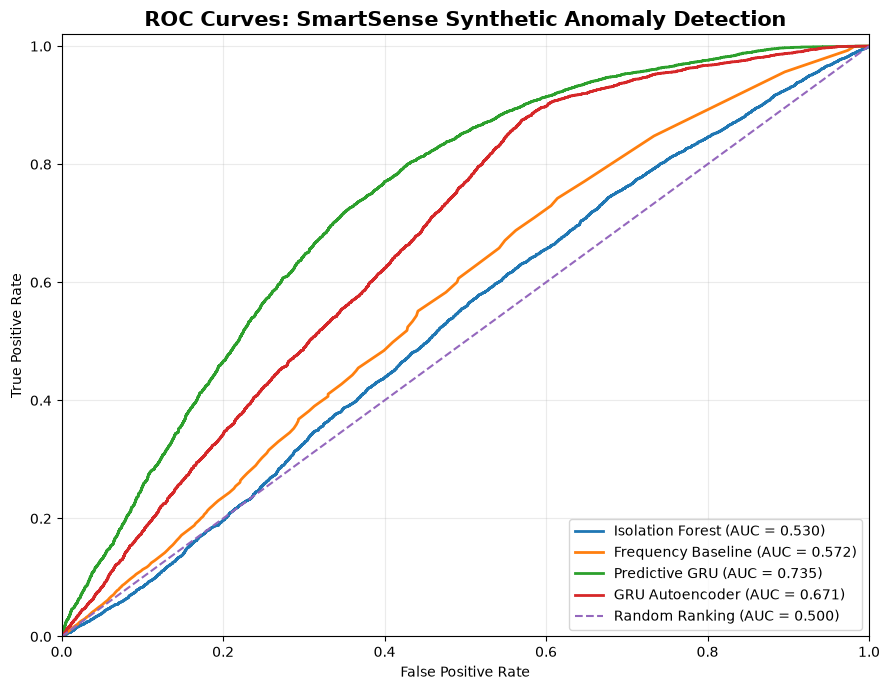

Figure saved to: figures\anomaly_detection\figure1_roc_curves.png


In [21]:
#Figure 1: ROC curves for anomaly detection

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score

# Create output directory
FIGURE_DIR = Path("figures/anomaly_detection")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Use the frequency-informed evaluation dataset
labels = y_eval_matched

model_scores = {
    "Isolation Forest": isolation_scores_matched,
    "Frequency Baseline": frequency_scores_matched,
    "Predictive GRU": gru_scores_matched,
    "GRU Autoencoder": ae_scores_matched
}

fig, ax = plt.subplots(figsize=(9, 7))

# Plot ROC curve for each model
for model_name, scores in model_scores.items():

    fpr, tpr, thresholds = roc_curve(
        labels,
        scores
    )

    auc = roc_auc_score(
        labels,
        scores
    )

    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {auc:.3f})"
    )

# Random ranking reference
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Ranking (AUC = 0.500)"
)

ax.set_title(
    "ROC Curves: SmartSense Synthetic Anomaly Detection",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(loc="lower right")
ax.grid(alpha=0.25)

plt.tight_layout()

# Save high-resolution image
output_path = (
    FIGURE_DIR / "figure1_roc_curves.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", output_path)


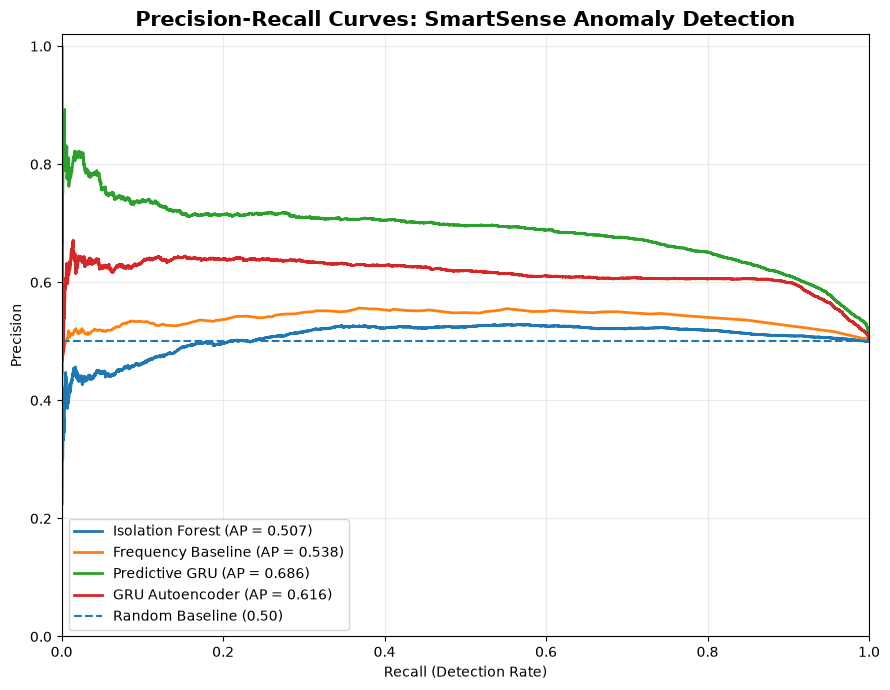

Figure saved to: figures\anomaly_detection\figure2_precision_recall_curves.png


In [22]:
#Figure 2: Precision-recall curves

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# Use frequency-informed synthetic anomaly dataset
labels = y_eval_matched

model_scores = {
    "Isolation Forest": isolation_scores_matched,
    "Frequency Baseline": frequency_scores_matched,
    "Predictive GRU": gru_scores_matched,
    "GRU Autoencoder": ae_scores_matched
}

fig, ax = plt.subplots(figsize=(9, 7))

for model_name, scores in model_scores.items():

    precision, recall, thresholds = precision_recall_curve(
        labels,
        scores
    )

    ap = average_precision_score(
        labels,
        scores
    )

    ax.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{model_name} (AP = {ap:.3f})"
    )

# Baseline precision = anomaly prevalence
baseline_precision = labels.mean()

ax.axhline(
    baseline_precision,
    linestyle="--",
    linewidth=1.5,
    label=f"Random Baseline ({baseline_precision:.2f})"
)

ax.set_title(
    "Precision-Recall Curves: SmartSense Anomaly Detection",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Recall (Detection Rate)")
ax.set_ylabel("Precision")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(loc="lower left")
ax.grid(alpha=0.25)

plt.tight_layout()

output_path = (
    FIGURE_DIR / "figure2_precision_recall_curves.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", output_path)


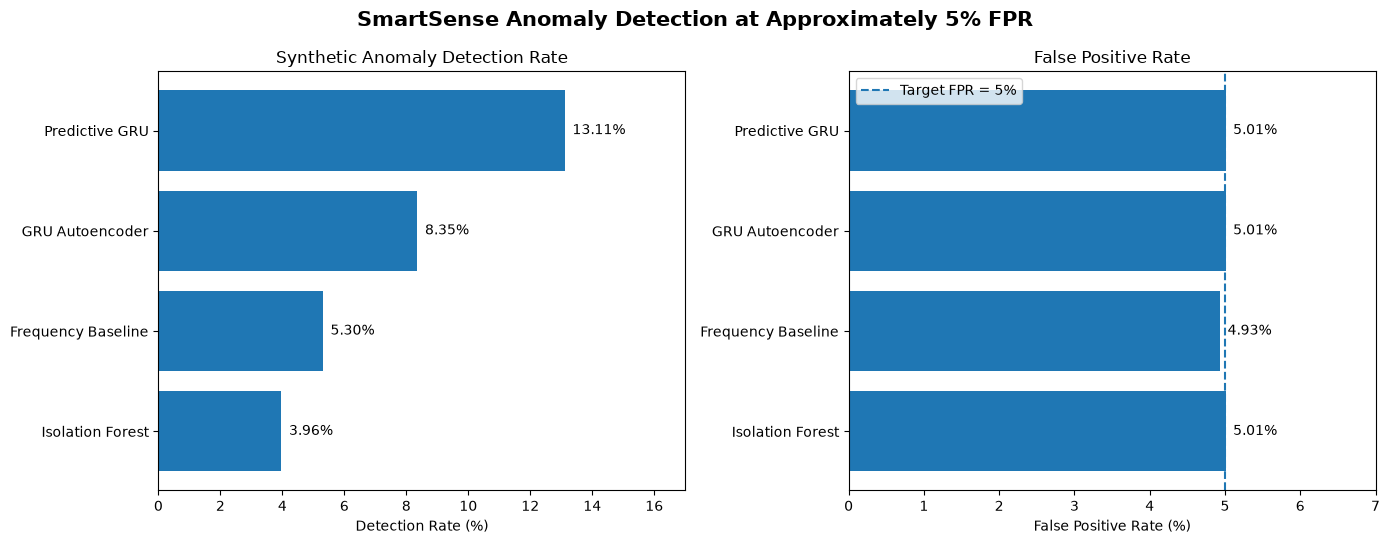

Figure saved to: figures\anomaly_detection\figure3_detection_at_5pct_fpr.png


In [23]:
#Figure 3: Detection performance at ~5% FPR

import numpy as np
import matplotlib.pyplot as plt

# Use results from Cell 20
plot_df = threshold_comparison.copy()

# Sort by detection rate
plot_df = plot_df.sort_values(
    "Detection Rate (%)",
    ascending=True
)

models = plot_df["Model"].values
detection = plot_df["Detection Rate (%)"].values
false_positive = plot_df["False Positive Rate (%)"].values

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5)
)

# Panel A - Detection rates
bars1 = axes[0].barh(
    models,
    detection
)

axes[0].set_title(
    "Synthetic Anomaly Detection Rate"
)

axes[0].set_xlabel("Detection Rate (%)")
axes[0].set_xlim(0, 17)

for bar in bars1:
    width = bar.get_width()

    axes[0].text(
        width + 0.25,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )

# Panel B - False positive rates
bars2 = axes[1].barh(
    models,
    false_positive
)

axes[1].set_title(
    "False Positive Rate"
)

axes[1].set_xlabel("False Positive Rate (%)")
axes[1].set_xlim(0, 7)

axes[1].axvline(
    5,
    linestyle="--",
    label="Target FPR = 5%"
)

for bar in bars2:
    width = bar.get_width()

    axes[1].text(
        width + 0.1,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )

axes[1].legend()

fig.suptitle(
    "SmartSense Anomaly Detection at Approximately 5% FPR",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

output_path = (
    FIGURE_DIR / "figure3_detection_at_5pct_fpr.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", output_path)


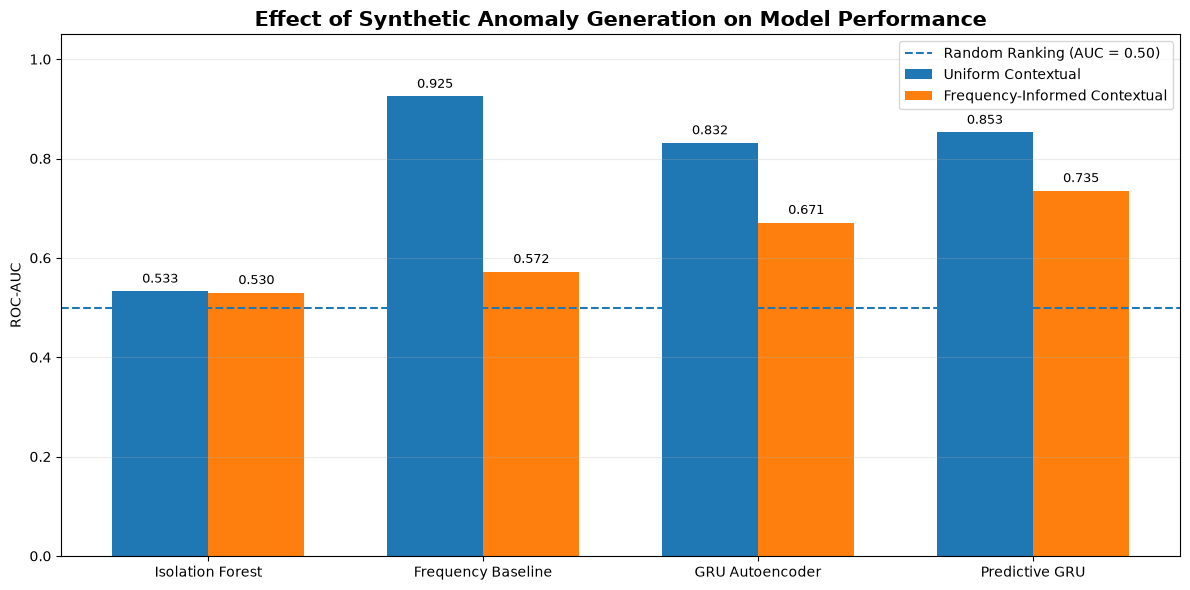

Figure saved to: figures\anomaly_detection\figure4_anomaly_generation_comparison.png


In [24]:
#Figure 4: Effect of anomaly generation strategy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the results calculated in Cell 19
plot_df = complete_anomaly_results.copy()

# Reshape results for grouped bar chart
auc_pivot = plot_df.pivot(
    index="Model",
    columns="Dataset",
    values="ROC-AUC"
)

# Set model order
model_order = [
    "Isolation Forest",
    "Frequency Baseline",
    "GRU Autoencoder",
    "GRU Anomaly Detector"
]

auc_pivot = auc_pivot.loc[model_order]

x = np.arange(len(model_order))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

bars_uniform = ax.bar(
    x - width / 2,
    auc_pivot["Uniform Contextual"],
    width,
    label="Uniform Contextual"
)

bars_matched = ax.bar(
    x + width / 2,
    auc_pivot["Frequency-Informed Contextual"],
    width,
    label="Frequency-Informed Contextual"
)

# Random ranking baseline
ax.axhline(
    0.5,
    linestyle="--",
    linewidth=1.5,
    label="Random Ranking (AUC = 0.50)"
)

ax.set_title(
    "Effect of Synthetic Anomaly Generation on Model Performance",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("ROC-AUC")
ax.set_xticks(x)
ax.set_xticklabels([
    "Isolation Forest",
    "Frequency Baseline",
    "GRU Autoencoder",
    "Predictive GRU"
])

ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.25)

# Add value labels
for bars in [bars_uniform, bars_matched]:
    for bar in bars:
        height = bar.get_height()

        ax.annotate(
            f"{height:.3f}",
            (
                bar.get_x() + bar.get_width() / 2,
                height
            ),
            ha="center",
            va="bottom",
            xytext=(0, 4),
            textcoords="offset points",
            fontsize=9
        )

plt.tight_layout()

output_path = (
    FIGURE_DIR / "figure4_anomaly_generation_comparison.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", output_path)


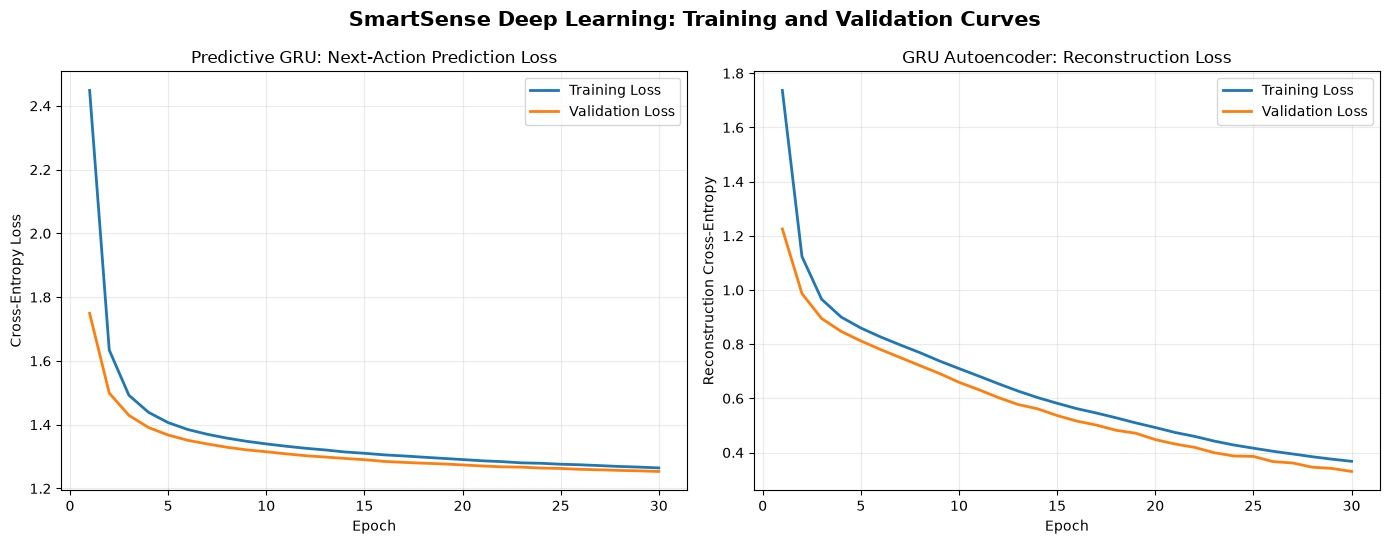

Figure saved to: figures\anomaly_detection\figure5_deep_learning_training_curves.png


In [25]:
#Figure 5: Deep learning training curves

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5)
)

# ---------------------------------------
# Panel A - Predictive GRU
# ---------------------------------------

gru_epochs = np.arange(
    1,
    len(anomaly_gru_history["train_loss"]) + 1
)

axes[0].plot(
    gru_epochs,
    anomaly_gru_history["train_loss"],
    linewidth=2,
    label="Training Loss"
)

axes[0].plot(
    gru_epochs,
    anomaly_gru_history["val_loss"],
    linewidth=2,
    label="Validation Loss"
)

axes[0].set_title(
    "Predictive GRU: Next-Action Prediction Loss"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(alpha=0.25)

# ---------------------------------------
# Panel B - GRU Autoencoder
# ---------------------------------------

ae_epochs = np.arange(
    1,
    len(ae_history["train_loss"]) + 1
)

axes[1].plot(
    ae_epochs,
    ae_history["train_loss"],
    linewidth=2,
    label="Training Loss"
)

axes[1].plot(
    ae_epochs,
    ae_history["val_loss"],
    linewidth=2,
    label="Validation Loss"
)

axes[1].set_title(
    "GRU Autoencoder: Reconstruction Loss"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Reconstruction Cross-Entropy")
axes[1].legend()
axes[1].grid(alpha=0.25)

fig.suptitle(
    "SmartSense Deep Learning: Training and Validation Curves",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

output_path = (
    FIGURE_DIR / "figure5_deep_learning_training_curves.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", output_path)
